# ARTI AI 검증 노트북 — 취향 태그(추천) · 감정(설명)

ARTI는 작품 그림을 오픈소스 AI로 분석해 두 가지를 만듭니다.

| | 무엇 | 어디에 쓰나 | 모델 |
|---|---|---|---|
| **취향 태그 8개** | 풍경 · 인물 · 추상 · 빛 · 강렬한 색감 · 차가운 색감 · 따뜻한 색감 · 부드러운 색감 (태그마다 0~1) | **추천** — 사용자 취향 카드 = 관리자 태그 = AI 태그 (같은 8개) | CLIP (그림 없으면 mDeBERTa로 해설에서) |
| **감정 6개** | 평온 · 기쁨 · 슬픔 · 긴장 · 경외 · 그리움 | 작품 분위기 설명(U-10), 아트 영수증(U-12) — 추천에는 쓰지 않음 | CLIP + mDeBERTa |

> **전제:** 두 모델 모두 **파인튜닝(추가 학습) 없이** 사전학습 모델을 그대로 쓰는 **제로샷** 방식입니다.
> 우리가 한 일은 ① 문장(프롬프트) 설계, ② 감정 라벨 편향 보정, ③ 모델 비교·선택입니다.

**구성**
- **1부 취향 태그** — 1-1 태그 정의 · 1-2 WikiArt 70점 분석 · 1-3 풍경·인물을 장르 정답과 비교 · 1-4 추상 · 1-5 색·빛 태그를 픽셀 측정값과 비교 · 1-6 채도 조절 실험 · 1-7 그림 갤러리 · 1-8 **캡처한 40점 정확도** · 1-9 추천 예시
- **2부 감정 (설명용)** — 텍스트 정확도·라벨 편향·혼동 행렬·모델 비교·CLIP 감정 갤러리·이미지+텍스트 결합
- **3부 팀 라벨 일치도** · **결론**

**실행 방법**
- **VS Code / Jupyter (로컬):** `ai-service/.venv`를 커널로 선택하고 `pip install matplotlib pandas ipykernel` 후 위에서부터 실행
- **Google Colab:** `ai-service` 폴더를 zip으로 압축해 왼쪽 「파일」 탭에 `ai-service.zip`으로 올린 뒤 위에서부터 실행 (모델 약 1.7GB, WikiArt 그림 약 80점 자동 다운로드)

## 0. 실행 환경 준비

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab: 업로드한 ai-service.zip 풀기 + 한글 폰트 설치 (torch·transformers는 Colab에 기본 설치되어 있음)
    if not os.path.exists("ai-service") and os.path.exists("ai-service.zip"):
        subprocess.run(["unzip", "-q", "ai-service.zip"], check=True)
    os.chdir("ai-service")
    subprocess.run('pip -q install "transformers>=4.46,<5" sentencepiece protobuf', shell=True)
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
elif os.path.basename(os.getcwd()) == "evaluation":
    os.chdir("..")  # 로컬: evaluation 폴더에서 열었으면 ai-service 폴더로 이동

sys.path.insert(0, os.getcwd())
print("작업 폴더:", os.getcwd())

작업 폴더: /home/user/arti/ai-service


In [2]:
import json, math, time, re, io, urllib.request, logging, warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

from app.emotions import EMOTIONS, EMOTION_KEYS
from app.analyzer import HuggingFaceScorer, apply_prior, combine, load_calibration, normalize_sum, scale_to_max
from app import config
from app.analyzer import calibrate_tags, load_tag_thresholds
from app.tags import TAG_KEYS, TAGS

# 실행과 상관없는 경고 메시지 숨기기
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)


def set_korean_font():
    # 한글이 깨지지 않도록 설치된 한글 폰트를 찾아 사용 (Windows: 맑은 고딕, Mac: AppleGothic, Colab: 나눔고딕)
    for path in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf"]:
        if os.path.exists(path):
            font_manager.fontManager.addfont(path)
    names = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "WenQuanYi Zen Hei"]:
        if name in names:
            plt.rcParams["font.family"] = name
            break
    plt.rcParams["axes.unicode_minus"] = False


set_korean_font()
pd.set_option("display.max_colwidth", 60)

KO = {e["key"]: e["ko"] for e in EMOTIONS}
KO_LIST = [KO[k] for k in EMOTION_KEYS]
TAG_KO = {t["key"]: t["ko"] for t in TAGS}
TAG_LIST = [TAG_KO[k] for k in TAG_KEYS]
TAG_THRESHOLD = 0.5  # 서비스 점수(태그별 기준값 보정 후) 0.5 이상 = "해당함" (backend/src/lib/tags.ts)
TAG_CAL = load_tag_thresholds()  # app/tag_calibration.json 태그별 기준값
FIG_DIR = Path("evaluation/results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name, dpi=150):
    # 발표 자료·README에 쓸 수 있게 그래프를 PNG로도 저장
    fig.savefig(FIG_DIR / f"{name}.png", dpi=dpi, bbox_inches="tight")


def heatmap(ax, values, rows, cols, title, fmt="{:.2f}", cmap="Reds", vmax=None):
    im = ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else max(1e-9, np.nanmax(values)), aspect="auto")
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(rows)), rows)
    ax.set_title(title)
    top = np.nanmax(values) if vmax is None else vmax
    for i in range(len(rows)):
        for j in range(len(cols)):
            v = values[i][j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if v > top * 0.6 else "black")
    return im


print("한글 폰트:", plt.rcParams["font.family"])

한글 폰트: ['WenQuanYi Zen Hei']


## 1부. 취향 태그 (추천에 사용)

### 1-1. 태그 정의 — 태그마다 "해당하는 그림" vs "해당하지 않는 그림" 문장

CLIP이 그림을 두 문장 중 어느 쪽에 더 가깝게 보는지로 0~1 점수를 냅니다(`app/tags.py`). 태그마다 따로 판단하므로 한 그림이 여러 태그에 해당할 수 있습니다.
태그마다 **기준값**(`app/tag_calibration.json`, 캡처 40점으로 정함)을 넘으면 "해당함"입니다. 서비스는 기준값이 0.5가 되도록 점수를 다시 매겨 보내므로, 이 노트북의 **서비스 점수도 0.5 이상 = 해당함**입니다.

In [3]:
pd.DataFrame([{"키": t["key"], "태그": t["ko"], "기준값": TAG_CAL.get(t["key"], 0.5), "해당하는 그림 (CLIP 문장)": " / ".join(t["pos"]), "해당하지 않는 그림": " / ".join(t["neg"])} for t in TAGS])

,키,태그,기준값,해당하는 그림 (CLIP 문장),해당하지 않는 그림
0,landscape,풍경,0.50,a landscape painting of nature / a painting of mountains...,a portrait or figure painting / a painting of objects or...
1,people,인물,0.50,a painting of a person / a portrait or a scene with people,a painting with no people in it / an empty landscape or ...
2,abstract,추상,0.50,"an abstract painting of shapes, lines and colors / a non...",a realistic painting of recognizable things / a figurati...
3,light,빛,0.95,a painting with luminous light glowing in the darkness /...,"a painting with flat, even, uninteresting lighting"
4,vivid,강렬한 색감,0.90,"a vibrant, colorful painting","a muted, desaturated painting"
5,cool,차가운 색감,0.50,a painting dominated by cool blue and green tones / a bl...,"a painting dominated by warm red, orange and yellow tone..."
6,warm,따뜻한 색감,0.90,"a painting dominated by warm red, orange and yellow tone...",a painting dominated by cool blue and green tones / a bl...
7,soft,부드러운 색감,0.50,a painting with soft pastel colors / a gentle painting w...,"a painting with harsh, strong colors / a heavy, dark pai..."


### 1-2. WikiArt 70점 분석

공개 미술 데이터셋 [WikiArt (huggan/wikiart)](https://huggingface.co/datasets/huggan/wikiart)에는 작품마다 **장르(풍경화·초상화·정물화) 정답**이 붙어 있습니다.
개발자가 정한 정답이 아니라 **데이터셋의 공식 라벨**로 검증할 수 있다는 점이 감정 검증과 다릅니다.
화가가 고르게 섞이도록 고른 풍경화 20 · 초상화 20 · 정물화 15 · 입체주의 15점을 분석합니다.

In [4]:
IMG_DIR = Path("evaluation/images")  # 캡처 40점·WikiArt 그림 (팀 내부 실험용으로 Git에 포함)
IMG_DIR.mkdir(exist_ok=True)
ROWS_API = "https://datasets-server.huggingface.co/rows?dataset=huggan/wikiart&config=default&split=train&offset={}&length=1"


def wikiart_image(idx):
    # 데이터셋 행 번호로 그림을 내려받아 512px로 줄여 저장 (CLIP은 224px로 보므로 결과는 같음)
    path = IMG_DIR / f"wikiart_{idx}.jpg"
    for attempt in range(4):  # 공개 서버가 가끔 502를 돌려주므로 몇 번 다시 시도
        if path.exists():
            break
        try:
            row = json.load(urllib.request.urlopen(ROWS_API.format(idx), timeout=60))["rows"][0]["row"]
            img = Image.open(io.BytesIO(urllib.request.urlopen(row["image"]["src"], timeout=60).read())).convert("RGB")
            img.thumbnail((512, 512))
            img.save(path, quality=90)
        except OSError:
            if attempt == 3:
                raise
            time.sleep(3 * (attempt + 1))
    return Image.open(path).convert("RGB")


SAMPLE = {"landscape": [2078, 2517, 2203, 1068, 613, 2538, 92, 2877, 3377, 1354, 436, 158, 1295, 3962, 1677, 2213, 3736, 3529, 3547, 1872], "portrait": [2920, 3507, 3670, 350, 39, 3205, 495, 2190, 3503, 1738, 1890, 800, 917, 2003, 3527, 3488, 2884, 397, 3198, 876], "still_life": [537, 431, 600, 792, 1863, 1534, 949, 3241, 3130, 251, 3927, 3654, 577, 32, 1883], "cubism": [636, 260, 2223, 3785, 3187, 1380, 1208, 184, 364, 1212, 2111, 1918, 303, 3398, 201]}  # 그룹별 WikiArt 행 번호 (화가가 고르게 섞이도록 고정)
GROUP_KO = {"landscape": "풍경화", "portrait": "초상화", "still_life": "정물화", "cubism": "입체주의"}

scorer = HuggingFaceScorer()
scorer.load()


def service_tags(img):
    # 서비스와 같은 점수: CLIP 원점수 → 태그별 기준값이 0.5가 되도록 보정
    return calibrate_tags(scorer.image_tag_scores(img), TAG_CAL)


t0 = time.time()
recs = []
for group, ids in SAMPLE.items():
    for idx in ids:
        recs.append({"idx": idx, "group": group, **service_tags(wikiart_image(idx))})
tag_df = pd.DataFrame(recs)
print(f"{len(tag_df)}점 분석 · 그룹별 {dict(tag_df.group.map(GROUP_KO).value_counts())} · {time.time() - t0:.0f}초")
tag_df.groupby(tag_df.group.map(GROUP_KO))[TAG_KEYS].mean().rename(columns=TAG_KO).style.format("{:.2f}").background_gradient(cmap="Reds", axis=None)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Device set to use cpu


70점 분석 · 그룹별 {'풍경화': np.int64(20), '초상화': np.int64(20), '정물화': np.int64(15), '입체주의': np.int64(15)} · 53초


,풍경,인물,추상,빛,강렬한 색감,차가운 색감,따뜻한 색감,부드러운 색감
group,,,,,,,,
입체주의,0.18,0.72,0.44,0.35,0.26,0.18,0.60,0.08
정물화,0.01,0.28,0.18,0.46,0.32,0.23,0.66,0.24
초상화,0.01,0.98,0.29,0.43,0.18,0.13,0.65,0.23
풍경화,0.82,0.23,0.11,0.56,0.20,0.23,0.64,0.32


### 1-3. 풍경·인물 — 데이터셋의 장르 정답과 비교

기준값은 캡처 40점으로 정했으므로, 이 70점은 **기준값을 정할 때 쓰지 않은 별도 데이터**로 확인하는 셈입니다.

- **풍경** 정답 = 풍경화 / 아님 = 초상화·정물화
- **인물** 정답 = 초상화 / 아님 = 풍경화·정물화

| 지표 | 뜻 |
|---|---|
| 정확도 | 0.5 기준으로 "해당함/아님"을 맞힌 비율 |
| 정밀도 | AI가 "해당함"이라고 한 것 중 실제로 맞은 비율 |
| 재현율 | 실제로 해당하는 그림 중 AI가 찾아낸 비율 |
| AUC | 해당하는 그림이 아닌 그림보다 점수가 높을 확률 (0.5 = 무작위, 1 = 완벽) |

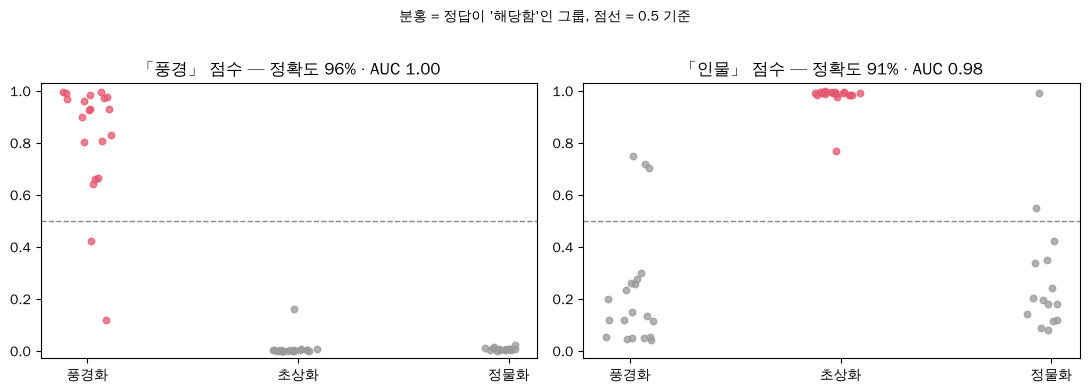

,정확도,정밀도,재현율,AUC,맞음/전체
풍경,96%,100%,90%,1.00,53/55
인물,91%,80%,100%,0.98,50/55


In [5]:
ev = tag_df[tag_df.group.isin(["landscape", "portrait", "still_life"])]
TRUTH = {"landscape": ev.group == "landscape", "people": ev.group == "portrait"}


def binary_metrics(scores, truth):
    pred = scores >= TAG_THRESHOLD
    tp, fp = int((pred & truth).sum()), int((pred & ~truth).sum())
    fn, tn = int((~pred & truth).sum()), int((~pred & ~truth).sum())
    pos, neg = scores[truth].values, scores[~truth].values
    auc = float(np.mean([(p > n) + 0.5 * (p == n) for p in pos for n in neg]))
    return {"정확도": (tp + tn) / len(truth), "정밀도": tp / max(tp + fp, 1), "재현율": tp / max(tp + fn, 1), "AUC": auc,
            "맞음/전체": f"{tp + tn}/{len(truth)}"}


subject_metrics = pd.DataFrame({TAG_KO[t]: binary_metrics(ev[t], y) for t, y in TRUTH.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, t in zip(axes, TRUTH):
    for j, g in enumerate(["landscape", "portrait", "still_life"]):
        v = ev[ev.group == g][t]
        ax.scatter(np.full(len(v), j) + np.random.RandomState(j).uniform(-0.12, 0.12, len(v)), v, s=22, alpha=0.75,
                   color="#e5576f" if TRUTH[t][ev.group == g].iloc[0] else "#999")
    ax.axhline(TAG_THRESHOLD, color="#888", ls="--", lw=1)
    ax.set_xticks([0, 1, 2], ["풍경화", "초상화", "정물화"]); ax.set_ylim(-0.03, 1.03)
    m = subject_metrics.loc[TAG_KO[t]]
    ax.set_title(f"「{TAG_KO[t]}」 점수 — 정확도 {m['정확도']:.0%} · AUC {m['AUC']:.2f}")
fig.suptitle("분홍 = 정답이 '해당함'인 그룹, 점선 = 0.5 기준", fontsize=10, y=1.02)
fig.tight_layout(); save(fig, "t1_subject_vs_genre"); plt.show()
subject_metrics.style.format({"정확도": "{:.0%}", "정밀도": "{:.0%}", "재현율": "{:.0%}", "AUC": "{:.2f}"})

### 1-4. 추상 — 입체주의 그림이 더 높게 나오나

이 데이터셋에는 완전한 추상화가 거의 없어(4,000점 중 1점), **반쯤 추상인 입체주의**가 사실적인 그림보다 높게 나오는지만 봅니다(정확도가 아니라 경향 확인).

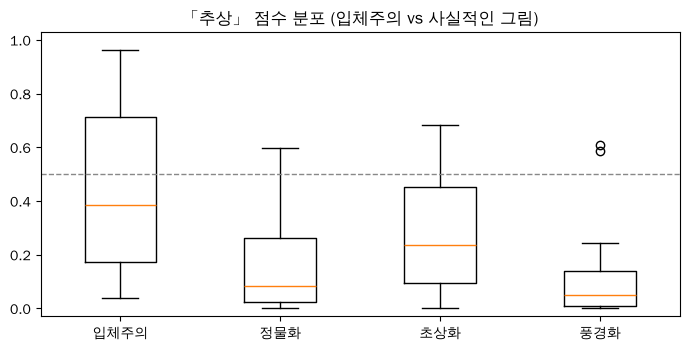

,평균,0.5 이상 비율
group,,
입체주의,0.44,0.40
정물화,0.18,0.13
초상화,0.29,0.20
풍경화,0.11,0.10


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
groups = ["cubism", "still_life", "portrait", "landscape"]
ax.boxplot([tag_df[tag_df.group == g]["abstract"] for g in groups], tick_labels=[GROUP_KO[g] for g in groups])
ax.axhline(TAG_THRESHOLD, color="#888", ls="--", lw=1); ax.set_ylim(-0.03, 1.03)
ax.set_title("「추상」 점수 분포 (입체주의 vs 사실적인 그림)")
fig.tight_layout(); save(fig, "t2_abstract_cubism"); plt.show()
abstract_share = tag_df.groupby(tag_df.group.map(GROUP_KO))["abstract"].agg(평균="mean", **{"0.5 이상 비율": lambda s: (s >= TAG_THRESHOLD).mean()})
abstract_share.style.format("{:.2f}")

### 1-5. 색·빛 태그 — 그림의 실제 픽셀 색과 비교

색감은 사람마다 판단이 달라 정답을 정하기 어렵지만, **픽셀을 직접 재면 객관적인 기준**이 생깁니다. 70점 모두에 대해 아래를 재서 AI 점수와 **순위 상관(스피어만, -1~1)**을 봅니다.

| AI 태그 | 픽셀 측정값 |
|---|---|
| 강렬한 색감 | 평균 채도 |
| 빛 | 평균 밝기 |
| 따뜻한 색감 | 색이 있는 픽셀 중 빨강~노랑 비율 |
| 차가운 색감 | 색이 있는 픽셀 중 초록~파랑 비율 |
| 부드러운 색감 | 밝기 × (1 − 채도) 평균 ("밝고 연한 정도") |

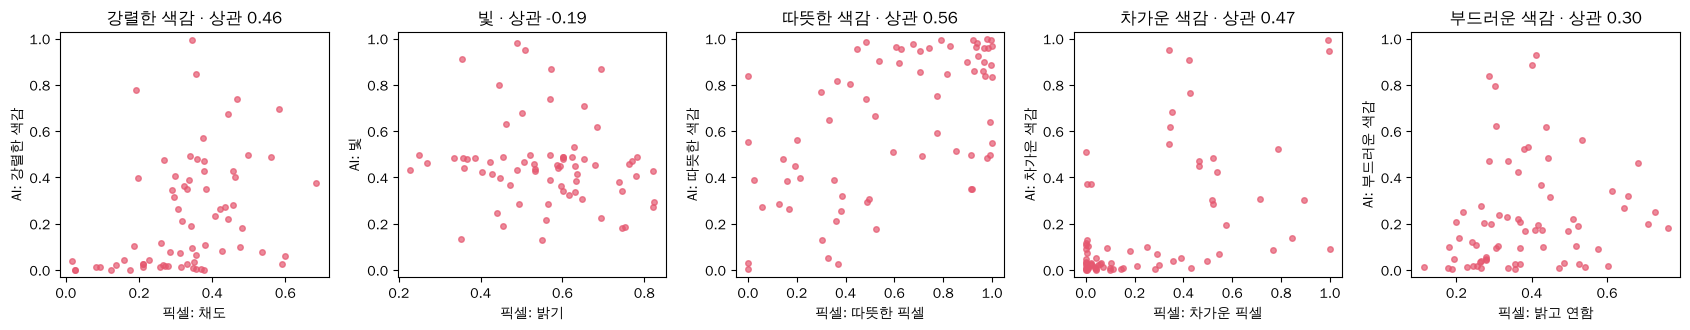

,스피어만 상관
강렬한 색감,0.46
빛,-0.19
따뜻한 색감,0.56
차가운 색감,0.47
부드러운 색감,0.30


In [7]:
def pixel_stats(img):
    hsv = np.asarray(img.convert("HSV").resize((128, 128)), dtype=float) / 255
    h, s, v = hsv[..., 0] * 360, hsv[..., 1], hsv[..., 2]
    colored = s > 0.15  # 회색에 가까운 픽셀은 색 판단에서 제외
    n = max(colored.sum(), 1)
    return {"채도": s.mean(), "밝기": v.mean(),
            "따뜻한 픽셀": (((h < 60) | (h >= 330)) & colored).sum() / n,
            "차가운 픽셀": (((h >= 90) & (h < 270)) & colored).sum() / n,
            "밝고 연함": (v * (1 - s)).mean()}


px = pd.DataFrame([pixel_stats(wikiart_image(i)) for i in tag_df.idx])
PAIRS = [("vivid", "채도"), ("light", "밝기"), ("warm", "따뜻한 픽셀"), ("cool", "차가운 픽셀"), ("soft", "밝고 연함")]
color_corr = {TAG_KO[t]: tag_df[t].rank().corr(px[m].rank()) for t, m in PAIRS}  # 순위끼리의 상관 = 스피어만 (scipy 없이)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (t, m) in zip(axes, PAIRS):
    ax.scatter(px[m], tag_df[t], s=16, alpha=0.7, color="#e5576f")
    ax.set_xlabel(f"픽셀: {m}"); ax.set_ylabel(f"AI: {TAG_KO[t]}"); ax.set_ylim(-0.03, 1.03)
    ax.set_title(f"{TAG_KO[t]} · 상관 {color_corr[TAG_KO[t]]:.2f}")
fig.tight_layout(); save(fig, "t3_color_vs_pixels"); plt.show()
pd.Series(color_corr, name="스피어만 상관").to_frame().style.format("{:.2f}")

### 1-6. 채도 조절 실험 — 같은 그림의 색만 바꾸면 「강렬한 색감」 점수가 따라 움직이나

그림 내용은 그대로 두고 채도만 0.25배 ~ 2.2배로 바꿔 봅니다. 점수가 채도를 따라 올라가면 AI가 그림의 **소재가 아니라 색**을 보고 판단한다는 근거가 됩니다.

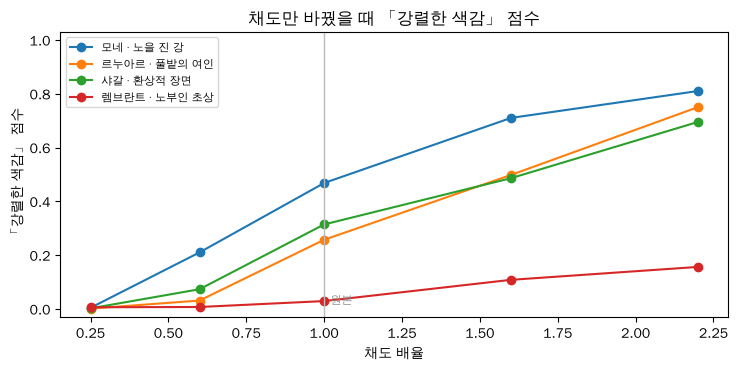

In [8]:
from PIL import ImageEnhance

FACTORS = [0.25, 0.6, 1.0, 1.6, 2.2]
SAT_IDS = [(71, "모네 · 노을 진 강"), (3, "르누아르 · 풀밭의 여인"), (68, "샤갈 · 환상적 장면"), (24, "렘브란트 · 노부인 초상")]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for idx, label in SAT_IDS:
    base_img = wikiart_image(idx)
    ys = [service_tags(ImageEnhance.Color(base_img).enhance(f))["vivid"] for f in FACTORS]
    ax.plot(FACTORS, ys, marker="o", label=label)
ax.axvline(1.0, color="#bbb", lw=1); ax.text(1.02, 0.02, "원본", color="#888", fontsize=8)
ax.set_xlabel("채도 배율"); ax.set_ylabel("「강렬한 색감」 점수"); ax.set_ylim(-0.03, 1.03)
ax.set_title("채도만 바꿨을 때 「강렬한 색감」 점수"); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "t4_saturation_test"); plt.show()

### 1-7. 그림 갤러리 — 태그 점수를 눈으로 확인

화가·장르가 다른 9점의 태그 8개 점수입니다(진한 막대 = 0.5 이상, "해당함").

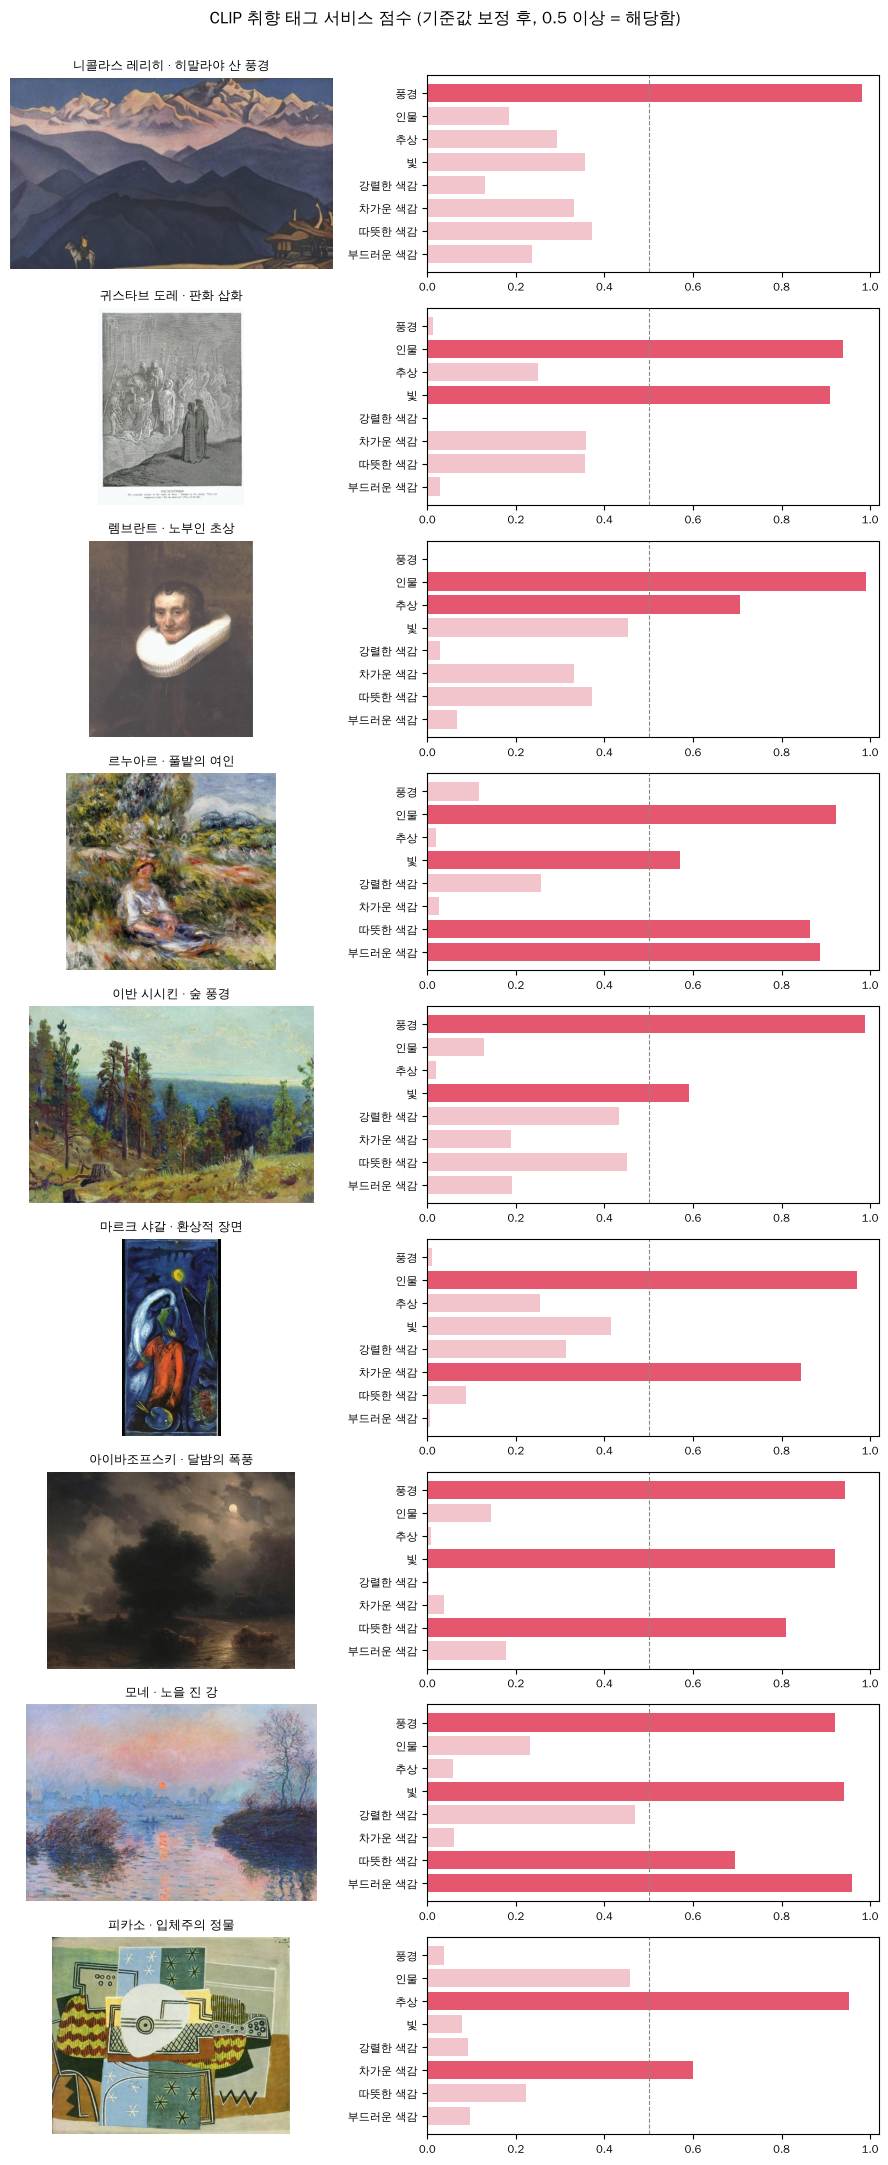

,그림,해당함 (0.5 이상)
0,니콜라스 레리히 · 히말라야 산 풍경,풍경
1,귀스타브 도레 · 판화 삽화,인물 · 빛
2,렘브란트 · 노부인 초상,인물 · 추상
3,르누아르 · 풀밭의 여인,인물 · 부드러운 색감 · 따뜻한 색감 · 빛
4,이반 시시킨 · 숲 풍경,풍경 · 빛
5,마르크 샤갈 · 환상적 장면,인물 · 차가운 색감
6,아이바조프스키 · 달밤의 폭풍,풍경 · 빛 · 따뜻한 색감
7,모네 · 노을 진 강,부드러운 색감 · 빛 · 풍경 · 따뜻한 색감
8,피카소 · 입체주의 정물,추상 · 차가운 색감


In [9]:
WIKIART = [  # (데이터셋 행 번호, 설명) — 2부 감정 갤러리에도 같은 9점을 씀
    (12, "니콜라스 레리히 · 히말라야 산 풍경"), (17, "귀스타브 도레 · 판화 삽화"), (24, "렘브란트 · 노부인 초상"),
    (3, "르누아르 · 풀밭의 여인"), (6026, "이반 시시킨 · 숲 풍경"), (68, "마르크 샤갈 · 환상적 장면"),
    (7, "아이바조프스키 · 달밤의 폭풍"), (71, "모네 · 노을 진 강"), (99, "피카소 · 입체주의 정물"),
]
tag_gallery = [(label, wikiart_image(idx), service_tags(wikiart_image(idx))) for idx, label in WIKIART]

fig, axes = plt.subplots(len(tag_gallery), 2, figsize=(9, 2.4 * len(tag_gallery)), gridspec_kw={"width_ratios": [1, 1.4]})
for r, (label, img, s) in enumerate(tag_gallery):
    axes[r][0].imshow(img); axes[r][0].axis("off"); axes[r][0].set_title(label, fontsize=9)
    vals = [s[k] for k in TAG_KEYS]
    axes[r][1].barh(TAG_LIST[::-1], vals[::-1], color=["#e5576f" if v >= TAG_THRESHOLD else "#f2c4cc" for v in vals[::-1]])
    axes[r][1].axvline(TAG_THRESHOLD, color="#888", ls="--", lw=0.8); axes[r][1].set_xlim(0, 1.02); axes[r][1].tick_params(labelsize=8)
fig.suptitle("CLIP 취향 태그 서비스 점수 (기준값 보정 후, 0.5 이상 = 해당함)", y=1.0)
fig.tight_layout(); save(fig, "t5_tag_gallery", dpi=80); plt.show()
pd.DataFrame([{"그림": l, "해당함 (0.5 이상)": " · ".join(TAG_KO[k] for k in sorted(TAG_KEYS, key=lambda k: -s[k]) if s[k] >= TAG_THRESHOLD)} for l, _, s in tag_gallery])

### 1-8. 캡처한 40점으로 정확도 재기 · 태그별 기준값 정하기 (`evaluation/tag_eval_set.json`)

태그마다 5점씩 고른 40점의 정답(대표 태그 + 함께 해당하는 태그, **팀원 6명 다수결** — `evaluation/team_tags.py`, 1-8-2 참고)과 캡처 그림(`evaluation/images/01.jpg ~ 40.jpg`)이 들어 있습니다.

| 방식 | 뜻 |
|---|---|
| 기준값 0.5 (조정 전) | 모든 태그를 0.5로 판단 |
| 태그별 기준값 (서비스) | `app/tag_calibration.json` — **이 40점으로 정한 값이라 같은 40점으로 재면 실제보다 좋게 나옴** |
| 교차검증 | 각 작품을 잴 때 **그 작품을 뺀 39점으로 기준값을 정함** → 처음 보는 그림에서 기대할 수 있는 값 |

지표: **대표 태그 적중률**(대표 태그가 "해당함"), 태그별 **F1**(정밀도와 재현율의 조화 평균). 정답 목록에 없는 태그는 "해당하지 않음"으로 계산합니다.

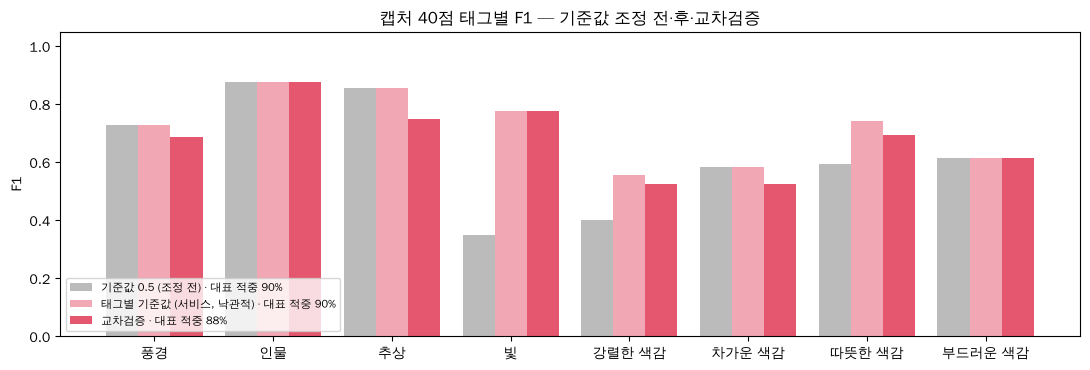

,기준값 0.5 (조정 전),"태그별 기준값 (서비스, 낙관적)",교차검증
대표 태그 적중률,90%,90%,88%
F1 풍경,73%,73%,69%
F1 인물,88%,88%,88%
F1 추상,86%,86%,75%
F1 빛,35%,78%,78%
F1 강렬한 색감,40%,56%,53%
F1 차가운 색감,58%,58%,53%
F1 따뜻한 색감,59%,74%,69%
F1 부드러운 색감,62%,62%,62%


이 40점으로 다시 계산한 기준값: {'landscape': 0.55, 'people': 0.55, 'abstract': 0.5, 'light': 0.95, 'vivid': 0.9, 'cool': 0.7, 'warm': 0.9, 'soft': 0.7}


,번호,작품,대표 태그,대표 점수,AI 해당함
0,01,모르트퐁텐의 추억,풍경,0.85,따뜻한 색감 · 빛 · 풍경
1,02,시에라네바다 산맥 속에서,풍경,1.00,풍경 · 빛 · 따뜻한 색감
2,03,미델하르니스의 가로수길,풍경,0.98,풍경
3,04,건초 마차,풍경,0.92,빛 · 풍경 · 따뜻한 색감
4,05,산 (〈산〉 연작 중 1점),따뜻한 색감,0.99,풍경 · 따뜻한 색감 · 추상 · 강렬한 색감
5,06,우유를 따르는 여인,인물,0.96,인물 · 차가운 색감
6,07,모나리자,인물,0.89,인물
7,08,야경,인물,0.85,따뜻한 색감 · 빛 · 인물
8,09,폴리베르제르의 술집,인물,0.82,인물
9,10,빨래터,인물,0.79,인물


In [10]:
tag_eval = json.loads(Path("evaluation/tag_eval_set.json").read_text(encoding="utf-8"))["items"]
SAVE_THRESHOLDS = False  # True로 바꾸면 아래에서 다시 계산한 기준값을 app/tag_calibration.json 에 저장 (서버 재시작 후 반영)
GRID = np.round(np.arange(0.2, 0.96, 0.05), 2)


def find_capture(it):
    base = Path("evaluation") / it["imagePath"]
    for ext in [".jpg", ".png", ".jpeg", ".webp"]:
        if base.with_suffix(ext).exists():
            return base.with_suffix(ext)
    return None


found = [(it, find_capture(it)) for it in tag_eval]
found = [(it, p) for it, p in found if p]
capture_metrics = None
if not found:
    print("캡처 그림이 없습니다. evaluation/images/01.jpg ~ 40.jpg 로 저장한 뒤 다시 실행하세요.")
else:
    raw_cap = [scorer.image_tag_scores(Image.open(p).convert("RGB")) for _, p in found]
    Y = {k: np.array([k in it["expected"] for it, _ in found]) for k in TAG_KEYS}
    R = {k: np.array([r[k] for r in raw_cap]) for k in TAG_KEYS}

    def f1(k, th, idx=None):
        idx = np.arange(len(found)) if idx is None else idx
        pred, y = R[k][idx] >= th, Y[k][idx]
        tp = (pred & y).sum()
        pr, rc = tp / max(pred.sum(), 1), tp / max(y.sum(), 1)
        return 2 * pr * rc / max(pr + rc, 1e-9), pr, rc

    def best_th(k, idx=None):  # F1이 가장 높은 기준값 (같으면 0.5에 가까운 값)
        return float(max(GRID, key=lambda th: (f1(k, th, idx)[0], -abs(th - 0.5))))

    # 교차검증: 작품마다 나머지 39점으로 정한 기준값으로 판단
    loo_pred = {k: np.zeros(len(found), bool) for k in TAG_KEYS}
    for i in range(len(found)):
        rest = np.array([j for j in range(len(found)) if j != i])
        for k in TAG_KEYS:
            loo_pred[k][i] = R[k][i] >= best_th(k, rest)

    def summarize(pred_fn):
        primary = np.mean([pred_fn(it["primary"], i) for i, (it, _) in enumerate(found)])
        f1s = {}
        for k in TAG_KEYS:
            pred = np.array([pred_fn(k, i) for i in range(len(found))]); y = Y[k]
            tp = (pred & y).sum(); pr, rc = tp / max(pred.sum(), 1), tp / max(y.sum(), 1)
            f1s[TAG_KO[k]] = 2 * pr * rc / max(pr + rc, 1e-9)
        return primary, f1s

    modes = {
        "기준값 0.5 (조정 전)": lambda k, i: R[k][i] >= 0.5,
        "태그별 기준값 (서비스, 낙관적)": lambda k, i: R[k][i] >= TAG_CAL.get(k, 0.5),
        "교차검증": lambda k, i: loo_pred[k][i],
    }
    res = {m: summarize(fn) for m, fn in modes.items()}
    cap_table = pd.DataFrame({m: {"대표 태그 적중률": r[0], **{f"F1 {t}": v for t, v in r[1].items()}} for m, r in res.items()})
    capture_metrics = {"작품 수": len(found), **{f"{m} 적중률": r[0] for m, r in res.items()}}

    fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(TAG_KEYS))
    for off, (m, c) in zip([-0.27, 0, 0.27], zip(res, ["#bbb", "#f2a7b4", "#e5576f"])):
        ax.bar(x + off, [res[m][1][TAG_KO[k]] for k in TAG_KEYS], 0.27, label=f"{m} · 대표 적중 {res[m][0]:.0%}", color=c)
    ax.set_xticks(x, TAG_LIST); ax.set_ylim(0, 1.05); ax.set_ylabel("F1"); ax.legend(fontsize=8, loc="lower left")
    ax.set_title(f"캡처 {len(found)}점 태그별 F1 — 기준값 조정 전·후·교차검증")
    fig.tight_layout(); save(fig, "t6_capture_per_tag"); plt.show()
    display(cap_table.style.format("{:.0%}"))

    new_th = {k: best_th(k) for k in TAG_KEYS}
    print("이 40점으로 다시 계산한 기준값:", new_th)
    if SAVE_THRESHOLDS:
        cal = Path("app/tag_calibration.json"); data = json.loads(cal.read_text(encoding="utf-8"))
        data["thresholds"] = new_th
        cal.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
        print("저장:", cal)

    svc = [calibrate_tags(r, TAG_CAL) for r in raw_cap]
    display(pd.DataFrame([{"번호": it["id"], "작품": it["title"], "대표 태그": TAG_KO[it["primary"]], "대표 점수": s_[it["primary"]],
                           "AI 해당함": " · ".join(TAG_KO[k] for k in sorted(TAG_KEYS, key=lambda k: -s_[k]) if s_[k] >= TAG_THRESHOLD)}
                          for (it, _), s_ in zip(found, svc)]).style.format({"대표 점수": "{:.2f}"}))

### 1-8-2. 팀 라벨 — 사람끼리 얼마나 일치하고, AI는 사람만큼 하나

팀원 6명이 40점에 각자 태그를 붙였습니다(`evaluation/labeling/` — 구글 폼 4명, 라벨링 페이지 2명). 김동섭은 그림마다 태그를 1개만 골라 **대표 태그에만** 반영했습니다.

- **kappa (Fleiss)**: 사람끼리 일치도. 1 = 완전 일치, 0 = 우연 수준, 0.6 이상이면 꽤 일치
- **사람 1명 일치율**: 평가자 1명의 답이 나머지 평가자 다수결과 같은 비율(동점 제외)의 평균
- **AI 일치율**: 같은 기준으로 AI(서비스 기준값)의 답이 나머지 평가자 다수결과 같은 비율
- **AUC**: 다수결 정답 기준, AI 점수가 "해당하는 그림"을 "해당하지 않는 그림"보다 높게 매기는 비율


평가자 6명 (태그 다수결 5명) · 대표 태그 kappa 0.40


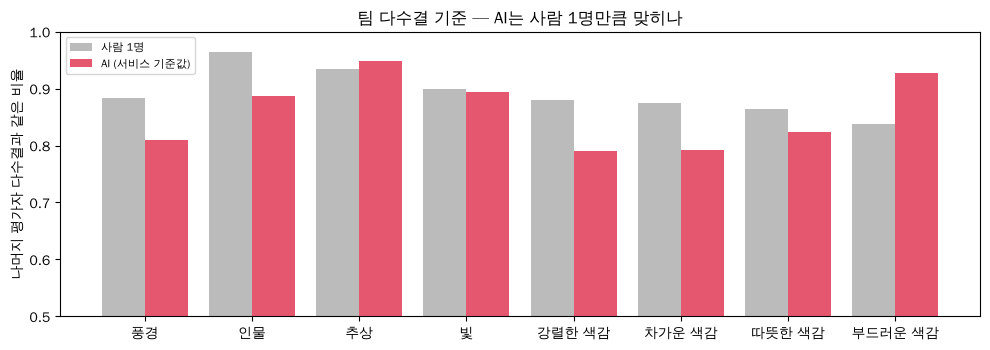

,kappa (사람끼리),사람 1명 일치율,AI 일치율,AUC (다수결 정답),kappa 해석
풍경,0.59,88%,81%,0.84,보통
인물,0.88,96%,89%,0.96,거의 완벽
추상,0.62,93%,95%,0.98,꽤 일치
빛,0.42,90%,89%,0.95,보통
강렬한 색감,0.38,88%,79%,0.89,약함
차가운 색감,0.51,88%,79%,0.89,보통
따뜻한 색감,0.47,86%,82%,0.93,보통
부드러운 색감,0.26,84%,93%,0.91,약함


In [11]:
from evaluation.team_tags import read_labels, aggregate, kappa_label

PRIMARY_ONLY = {"김동섭"}
team = read_labels()
if len(team) < 2 or not found:
    print("팀 라벨(evaluation/labeling/responses/)이나 캡처 그림이 없습니다.")
else:
    _, _, _, team_stats, _ = aggregate(team, tag_eval, PRIMARY_ONLY)
    multi = [r for r in team if r not in PRIMARY_ONLY]
    ids_ = [it["id"] for it, _ in found]
    svc_on = {k: np.array([r[k] >= TAG_CAL.get(k, 0.5) for r in raw_cap]) for k in TAG_KEYS}

    def agree(k, guess):  # guess(평가자 r, 작품 순번 j) → 해당함?  나머지 평가자 다수결과 같은 비율
        out = []
        for r in multi:
            others = [o for o in multi if o != r]
            hits = []
            for j, i in enumerate(ids_):
                v = sum(k in team[o][i]["tags"] for o in others)
                if v * 2 != len(others):
                    hits.append(guess(r, j) == (v * 2 > len(others)))
            out.append(np.mean(hits))
        return float(np.mean(out))

    def auc_(s, y):
        pos, neg = s[y], s[~y]
        return float(np.mean([(p > q) + 0.5 * (p == q) for p in pos for q in neg]))

    team_table = pd.DataFrame({
        TAG_KO[k]: {
            "kappa (사람끼리)": team_stats[k]["kappa"],
            "사람 1명 일치율": agree(k, lambda r, j, k=k: k in team[r][ids_[j]]["tags"]),
            "AI 일치율": agree(k, lambda r, j, k=k: bool(svc_on[k][j])),
            "AUC (다수결 정답)": auc_(R[k], Y[k]),
        } for k in TAG_KEYS
    }).T
    team_table["kappa 해석"] = [kappa_label(v) for v in team_table["kappa (사람끼리)"]]
    print(f"평가자 {len(team)}명 (태그 다수결 {len(multi)}명) · 대표 태그 kappa {team_stats['primary']['kappa']:.2f}")

    fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(TAG_KEYS))
    ax.bar(x - 0.2, team_table["사람 1명 일치율"], 0.4, label="사람 1명", color="#bbb")
    ax.bar(x + 0.2, team_table["AI 일치율"], 0.4, label="AI (서비스 기준값)", color="#e5576f")
    ax.set_xticks(x, TAG_LIST); ax.set_ylim(0.5, 1.0); ax.set_ylabel("나머지 평가자 다수결과 같은 비율"); ax.legend(fontsize=8)
    ax.set_title("팀 다수결 기준 — AI는 사람 1명만큼 맞히나")
    fig.tight_layout(); save(fig, "t7_team_vs_ai"); plt.show()
    display(team_table.style.format({"kappa (사람끼리)": "{:.2f}", "사람 1명 일치율": "{:.0%}", "AI 일치율": "{:.0%}", "AUC (다수결 정답)": "{:.2f}"}))


### 1-9. 추천 예시 — 위 갤러리 9점이 전시 작품이라면

서비스와 같은 규칙(`backend/src/lib/recommend.ts`): **점수 = 고른 카드의 태그 점수 평균**, 고른 카드마다 그 태그가 있는(0.5 이상) 작품을 먼저 1점씩, 나머지는 점수순. 변환표 없이 같은 단어끼리 바로 비교합니다.

In [12]:
KO2TAG = {v: k for k, v in TAG_KO.items()}


def recommend_tags(cards, works, n=3):
    keys = [KO2TAG[c] for c in cards]
    ranked = sorted(works, key=lambda w: -np.mean([w[2][k] for k in keys]))
    picked = []
    for k in keys[:n]:
        hit = next((w for w in ranked if w[2][k] >= TAG_THRESHOLD and w not in picked), None)
        if hit:
            picked.append(hit)
    for w in ranked:
        if len(picked) >= n:
            break
        if w not in picked:
            picked.append(w)
    return [(w[0], np.mean([w[2][k] for k in keys]), " · ".join(TAG_KO[k] for k in keys if w[2][k] >= TAG_THRESHOLD)) for w in picked]


rows = []
for cards in [("풍경", "빛"), ("인물", "따뜻한 색감"), ("차가운 색감", "따뜻한 색감")]:
    for rank_, (label, score, why) in enumerate(recommend_tags(cards, tag_gallery), 1):
        rows.append({"취향 카드": " + ".join(cards), "순위": rank_, "추천 작품": label, "점수": score, "추천 이유": why or "새로운 취향"})
pd.DataFrame(rows).style.format({"점수": "{:.2f}"})

,취향 카드,순위,추천 작품,점수,추천 이유
0,풍경 + 빛,1,아이바조프스키 · 달밤의 폭풍,0.93,풍경 · 빛
1,풍경 + 빛,2,모네 · 노을 진 강,0.93,풍경 · 빛
2,풍경 + 빛,3,이반 시시킨 · 숲 풍경,0.79,풍경 · 빛
3,인물 + 따뜻한 색감,1,르누아르 · 풀밭의 여인,0.89,인물 · 따뜻한 색감
4,인물 + 따뜻한 색감,2,아이바조프스키 · 달밤의 폭풍,0.48,따뜻한 색감
5,인물 + 따뜻한 색감,3,렘브란트 · 노부인 초상,0.68,인물
6,차가운 색감 + 따뜻한 색감,1,마르크 샤갈 · 환상적 장면,0.46,차가운 색감
7,차가운 색감 + 따뜻한 색감,2,르누아르 · 풀밭의 여인,0.45,따뜻한 색감
8,차가운 색감 + 따뜻한 색감,3,아이바조프스키 · 달밤의 폭풍,0.42,따뜻한 색감


## 2부. 감정 분석 (작품 분위기 설명용 — 추천에는 쓰지 않음)

### 2-1. 평가 데이터

`evaluation/eval_set.json`: 작품 해설 + 작품마다 **대표 감정 "정답" 1~2개**.

> ⚠️ **현재 정답은 1명(개발자)이 판단한 예시 라벨이고, 작품도 목업 11점뿐입니다.**
> 그래서 이 노트북의 정확도는 "대략적인 경향"으로만 봐야 합니다. 팀원 라벨을 모으는 방법은 3부에 있습니다.

In [13]:
data = json.loads(Path("evaluation/eval_set.json").read_text(encoding="utf-8"))
items = data["items"]
pd.DataFrame(
    [{"id": it["id"], "작품": it["title"], "작가": it["artist"],
      "정답 감정": ", ".join(KO[e] for e in it["expected"]), "해설 글자 수": len(it["description"])} for it in items]
)

,id,작품,작가,정답 감정,해설 글자 수
0,aw-01,별이 빛나는 밤,빈센트 반 고흐,"경외, 긴장",163
1,aw-02,수련,클로드 모네,평온,148
2,aw-03,붉은 방 (붉은색의 조화),앙리 마티스,기쁨,147
3,aw-04,해바라기,빈센트 반 고흐,기쁨,113
4,aw-05,"인상, 해돋이",클로드 모네,"평온, 그리움",125
5,aw-06,구성 VIII,바실리 칸딘스키,"기쁨, 긴장",107
6,aw-07,절규,에드바르 뭉크,"긴장, 슬픔",138
7,aw-08,그랑드자트섬의 일요일 오후,조르주 쇠라,"평온, 기쁨",103
8,aw-09,키스,구스타프 클림트,기쁨,106
9,aw-10,진주 귀고리를 한 소녀,요하네스 페르메이르,"평온, 그리움",117


### 2-2. 텍스트 분석 실행 (서비스와 같은 모델·문장)

서비스(`app/analyzer.py`)의 `HuggingFaceScorer.text_scores`를 그대로 호출합니다. 감정마다 0~1의 독립 확률(다중 라벨)이 나옵니다.
처음 실행하면 모델을 내려받느라 몇 분 걸리고, 이후에는 작품당 수 초입니다(CPU 기준).

작품 11점 분석 · 작품당 15.0초


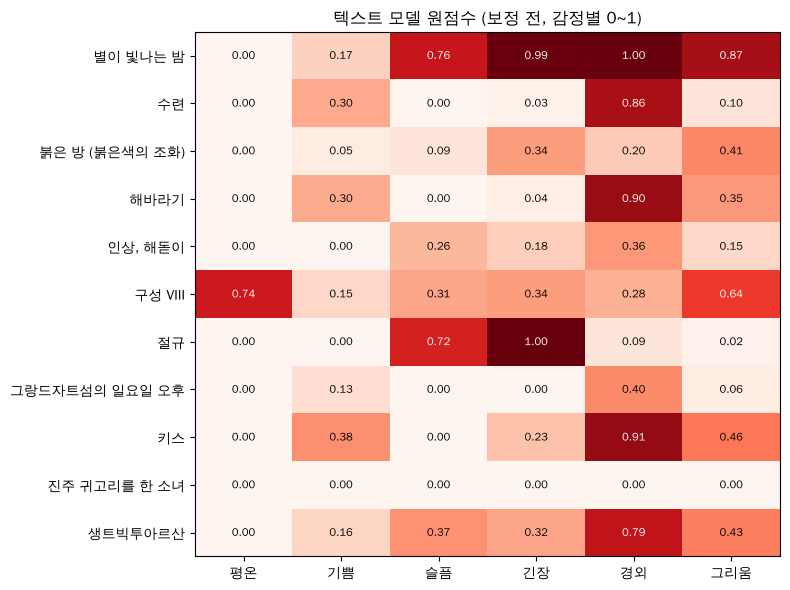

In [14]:
raw = {}
t0 = time.time()
for it in items:
    raw[it["id"]] = scorer.text_scores(it["description"])
sec_per_item = (time.time() - t0) / len(items)
print(f"작품 {len(items)}점 분석 · 작품당 {sec_per_item:.1f}초")

titles = [it["title"] for it in items]
raw_mat = np.array([[raw[it["id"]][k] for k in EMOTION_KEYS] for it in items])
fig, ax = plt.subplots(figsize=(8, 6))
heatmap(ax, raw_mat, titles, KO_LIST, "텍스트 모델 원점수 (보정 전, 감정별 0~1)", vmax=1)
fig.tight_layout(); save(fig, "01_text_raw_heatmap"); plt.show()

### 2-3. 라벨 편향 — 모델이 "어떤 글에나" 높게 주는 감정

제로샷 분류 모델은 내용과 상관없이 특정 라벨에 점수를 많이 주는 버릇(라벨 편향)이 있습니다.
모든 작품에 대한 **감정별 평균 점수**를 보면 바로 드러납니다.

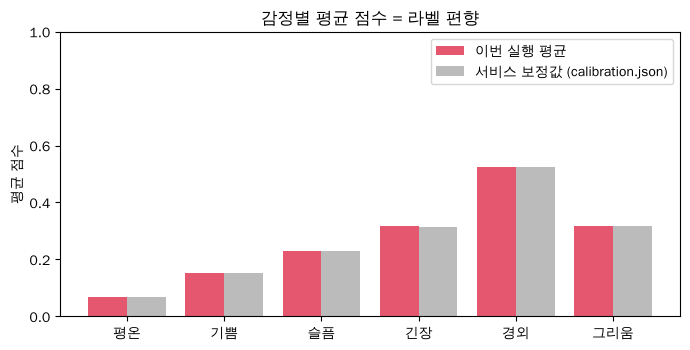

가장 많이 주는 감정: 경외 0.53 / 가장 적게 주는 감정: 평온 0.07


In [15]:
mean_scores = raw_mat.mean(axis=0)
prior_file = load_calibration().get("text", {})

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(EMOTION_KEYS))
ax.bar(x - 0.2, mean_scores, 0.4, label="이번 실행 평균", color="#e5576f")
if prior_file:
    ax.bar(x + 0.2, [prior_file[k] for k in EMOTION_KEYS], 0.4, label="서비스 보정값 (calibration.json)", color="#bbb")
ax.set_xticks(x, KO_LIST); ax.set_ylim(0, 1); ax.set_ylabel("평균 점수")
ax.set_title("감정별 평균 점수 = 라벨 편향")
ax.legend(); fig.tight_layout(); save(fig, "02_label_bias"); plt.show()

print("가장 많이 주는 감정:", KO[EMOTION_KEYS[int(mean_scores.argmax())]], f"{mean_scores.max():.2f}",
      "/ 가장 적게 주는 감정:", KO[EMOTION_KEYS[int(mean_scores.argmin())]], f"{mean_scores.min():.2f}")

### 2-4. 정확도 — 무작위 기준 · 보정 전후 · 교차검증

**지표**
- **Top-1:** AI의 1위 감정이 정답(1~2개) 안에 있는 비율
- **Top-2:** AI의 1·2위 중 하나라도 정답에 있는 비율

**비교하는 4가지**

| 이름 | 설명 |
|---|---|
| 무작위 기준 | 감정 6개 중 아무거나 골랐을 때 기대 정확도 (이것보다 높아야 의미가 있음) |
| 보정 전 | 모델 원점수 그대로 |
| 보정 (서비스) | 서비스가 실제로 쓰는 방식: `calibration.json`의 감정별 평균을 빼고 0 미만은 0 |
| 보정 (교차검증) | 각 작품을 평가할 때 **그 작품을 뺀 나머지 10점**으로 평균을 구해 보정 (Leave-One-Out) |

> 서비스 보정값은 **이 11점으로 만든 값**이라, 같은 11점으로 평가하면 실제보다 좋게 나올 수 있습니다.
> 교차검증 값이 **처음 보는 작품에서 기대할 수 있는 정확도**에 더 가깝습니다.

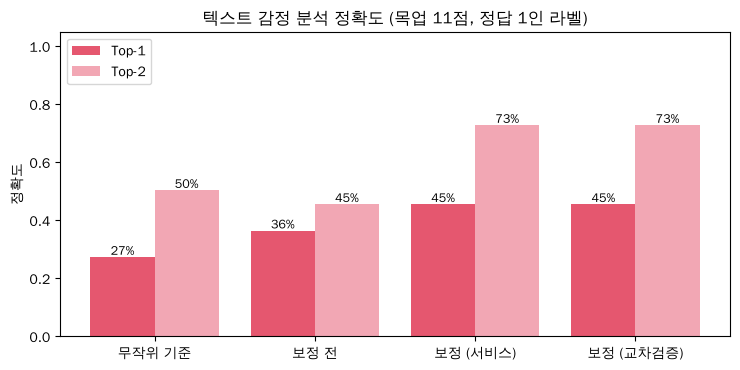

,방식,Top-1,Top-2
0,무작위 기준,27%,50%
1,보정 전,36%,45%
2,보정 (서비스),45%,73%
3,보정 (교차검증),45%,73%


In [16]:
def service_scores(raw_scores, prior):
    # 서비스 analyze()의 텍스트 경로와 동일: 편향 빼기 → 합 1로 정규화 → 최댓값 1로
    return scale_to_max(normalize_sum(apply_prior(raw_scores, prior)))


def rank(final, tiebreak):
    # 점수가 같으면(보정 후 0으로 잘린 감정 등) 원점수로 순위를 정함
    return sorted(EMOTION_KEYS, key=lambda k: (final[k], tiebreak[k]), reverse=True)


def accuracy(rankings):
    top1 = np.mean([rankings[it["id"]][0] in it["expected"] for it in items])
    top2 = np.mean([bool(set(rankings[it["id"]][:2]) & set(it["expected"])) for it in items])
    return top1, top2


# 무작위 기준: 정답 k개일 때 Top-1 = k/6, Top-2 = 1 - C(6-k,2)/C(6,2)
rand_top1 = np.mean([len(it["expected"]) / 6 for it in items])
rand_top2 = np.mean([1 - math.comb(6 - len(it["expected"]), 2) / math.comb(6, 2) for it in items])

rank_raw = {i: rank(raw[i], raw[i]) for i in raw}
final_service = {i: service_scores(raw[i], prior_file) for i in raw}
rank_service = {i: rank(final_service[i], raw[i]) for i in raw}

final_loo = {}
for it in items:
    others = [raw[o["id"]] for o in items if o["id"] != it["id"]]
    prior_loo = {k: float(np.mean([s[k] for s in others])) for k in EMOTION_KEYS}
    final_loo[it["id"]] = service_scores(raw[it["id"]], prior_loo)
rank_loo = {i: rank(final_loo[i], raw[i]) for i in raw}

acc = pd.DataFrame(
    [("무작위 기준", rand_top1, rand_top2), ("보정 전", *accuracy(rank_raw)),
     ("보정 (서비스)", *accuracy(rank_service)), ("보정 (교차검증)", *accuracy(rank_loo))],
    columns=["방식", "Top-1", "Top-2"],
)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(acc))
b1 = ax.bar(x - 0.2, acc["Top-1"], 0.4, label="Top-1", color="#e5576f")
b2 = ax.bar(x + 0.2, acc["Top-2"], 0.4, label="Top-2", color="#f2a7b4")
ax.bar_label(b1, labels=[f"{v:.0%}" for v in acc["Top-1"]], fontsize=9)
ax.bar_label(b2, labels=[f"{v:.0%}" for v in acc["Top-2"]], fontsize=9)
ax.set_xticks(x, acc["방식"]); ax.set_ylim(0, 1.05); ax.set_ylabel("정확도")
ax.set_title(f"텍스트 감정 분석 정확도 (목업 {len(items)}점, 정답 1인 라벨)")
ax.legend(loc="upper left"); fig.tight_layout(); save(fig, "03_accuracy"); plt.show()
acc.style.format({"Top-1": "{:.0%}", "Top-2": "{:.0%}"})

In [17]:
# 작품별 결과: 보정 전/후 1·2위와 정답 비교
rows = []
for it in items:
    i = it["id"]
    mark = lambda r: " ✅" if r[0] in it["expected"] else ""
    rows.append({
        "작품": it["title"], "정답": ", ".join(KO[e] for e in it["expected"]),
        "보정 전 1·2위": f"{KO[rank_raw[i][0]]}, {KO[rank_raw[i][1]]}{mark(rank_raw[i])}",
        "서비스 1·2위": f"{KO[rank_service[i][0]]}, {KO[rank_service[i][1]]}{mark(rank_service[i])}",
        "교차검증 1·2위": f"{KO[rank_loo[i][0]]}, {KO[rank_loo[i][1]]}{mark(rank_loo[i])}",
    })
pd.DataFrame(rows)

,작품,정답,보정 전 1·2위,서비스 1·2위,교차검증 1·2위
0,별이 빛나는 밤,"경외, 긴장","경외, 긴장 ✅","긴장, 그리움 ✅","긴장, 그리움 ✅"
1,수련,평온,"경외, 기쁨","경외, 기쁨","경외, 기쁨"
2,붉은 방 (붉은색의 조화),기쁨,"그리움, 긴장","그리움, 긴장","그리움, 긴장"
3,해바라기,기쁨,"경외, 그리움","경외, 기쁨","경외, 기쁨"
4,"인상, 해돋이","평온, 그리움","경외, 슬픔","슬픔, 평온","슬픔, 평온"
5,구성 VIII,"기쁨, 긴장","평온, 그리움","평온, 그리움","평온, 그리움"
6,절규,"긴장, 슬픔","긴장, 슬픔 ✅","긴장, 슬픔 ✅","긴장, 슬픔 ✅"
7,그랑드자트섬의 일요일 오후,"평온, 기쁨","경외, 기쁨","기쁨, 평온 ✅","기쁨, 평온 ✅"
8,키스,기쁨,"경외, 그리움","경외, 기쁨","경외, 기쁨"
9,진주 귀고리를 한 소녀,"평온, 그리움","그리움, 평온 ✅","평온, 기쁨 ✅","평온, 기쁨 ✅"


### 2-5. 혼동 행렬 — 어떤 감정을 어떤 감정으로 착각하나

행 = 정답(대표 감정, 첫 번째), 열 = 서비스 방식의 1위 예측. 대각선에 몰릴수록 좋습니다.

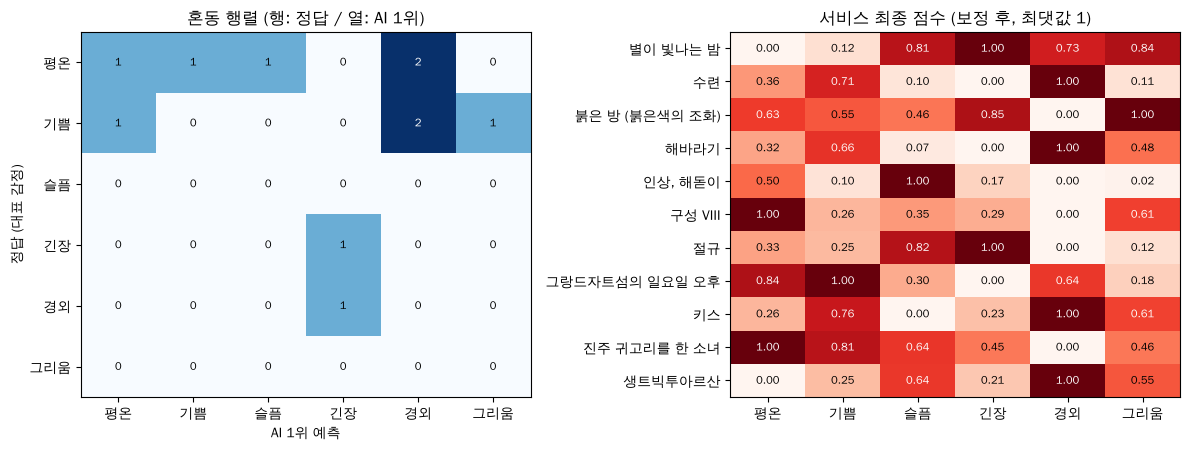

AI가 1위로 고른 감정 분포: {'경외': np.int64(4), '긴장': np.int64(2), '평온': np.int64(2), '그리움': np.int64(1), '슬픔': np.int64(1), '기쁨': np.int64(1)}


In [18]:
conf = np.zeros((6, 6), dtype=int)
for it in items:
    conf[EMOTION_KEYS.index(it["expected"][0]), EMOTION_KEYS.index(rank_service[it["id"]][0])] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
heatmap(axes[0], conf, KO_LIST, KO_LIST, "혼동 행렬 (행: 정답 / 열: AI 1위)", fmt="{:.0f}", cmap="Blues")
axes[0].set_xlabel("AI 1위 예측"); axes[0].set_ylabel("정답 (대표 감정)")

svc_mat = np.array([[final_service[it["id"]][k] for k in EMOTION_KEYS] for it in items])
heatmap(axes[1], svc_mat, titles, KO_LIST, "서비스 최종 점수 (보정 후, 최댓값 1)", vmax=1)
fig.tight_layout(); save(fig, "04_confusion_and_service_scores"); plt.show()

pred_counts = pd.Series([KO[rank_service[i][0]] for i in rank_service]).value_counts()
print("AI가 1위로 고른 감정 분포:", dict(pred_counts))

### 2-6. 텍스트 모델 비교 (같은 데이터, 모델·설정 4종)

`python -m evaluation.evaluate`로 저장해 둔 결과(`evaluation/results/details.csv`)를 불러와 비교합니다.
`RUN_ALL = True`로 바꾸면 4개 모델을 다시 내려받아 처음부터 실행합니다(CPU로 10~20분).

> 이 표의 「+보정」은 같은 11점 평균을 빼는 방식이라 2-4의 「보정 (서비스)」처럼 낙관적인 값입니다.

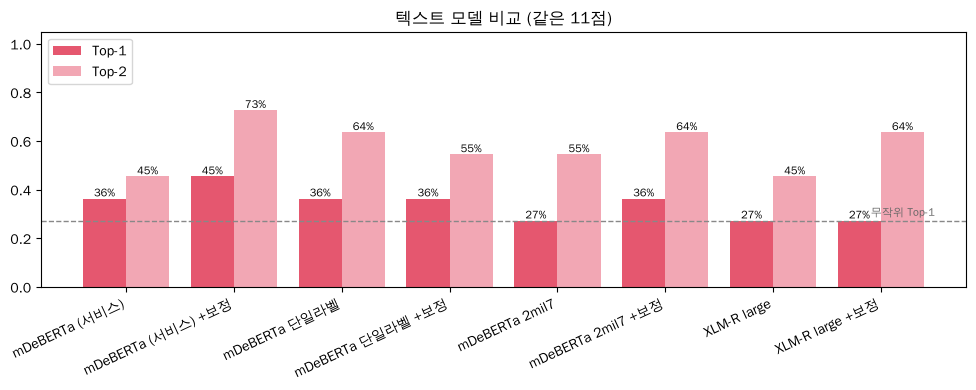

,모델,Top-1,Top-2,작품당 초
0,mDeBERTa (서비스),36%,45%,10.6
1,mDeBERTa (서비스) +보정,45%,73%,10.6
2,mDeBERTa 단일라벨,36%,64%,10.5
3,mDeBERTa 단일라벨 +보정,36%,55%,10.5
4,mDeBERTa 2mil7,27%,55%,12.8
5,mDeBERTa 2mil7 +보정,36%,64%,12.8
6,XLM-R large,27%,45%,2.5
7,XLM-R large +보정,27%,64%,2.5


In [19]:
RUN_ALL = False

if RUN_ALL:
    subprocess.run([sys.executable, "-m", "evaluation.evaluate"], check=True)

details = pd.read_csv("evaluation/results/details.csv", encoding="utf-8-sig")
expected_by_title = {it["title"]: {KO[e] for e in it["expected"]} for it in items}


def cfg_acc(g):
    t1 = np.mean([r["1위"] in expected_by_title[r["작품"]] for _, r in g.iterrows()])
    t2 = np.mean([bool({r["1위"], r["2위"]} & expected_by_title[r["작품"]]) for _, r in g.iterrows()])
    return pd.Series({"Top-1": t1, "Top-2": t2})


cmp = details.groupby("설정", sort=False).apply(cfg_acc).reset_index()

# 작품당 처리 시간은 report.md 표에서 읽음
times = {}
for line in Path("evaluation/results/report.md").read_text(encoding="utf-8").splitlines():
    m = re.match(r"\|\s*([^|]+?)\s*\|.*\|\s*([\d.]+)초\s*\|$", line)
    if m:
        times[m.group(1)] = float(m.group(2))
cmp["작품당 초"] = cmp["설정"].map(times)

NAMES = {"current": "mDeBERTa (서비스)", "single": "mDeBERTa 단일라벨", "2mil7": "mDeBERTa 2mil7", "large": "XLM-R large"}
cmp["모델"] = cmp["설정"].map(lambda s: NAMES.get(s.replace("+보정", ""), s) + (" +보정" if "+보정" in s else ""))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cmp))
b1 = ax.bar(x - 0.2, cmp["Top-1"], 0.4, label="Top-1", color="#e5576f")
b2 = ax.bar(x + 0.2, cmp["Top-2"], 0.4, label="Top-2", color="#f2a7b4")
ax.bar_label(b1, labels=[f"{v:.0%}" for v in cmp["Top-1"]], fontsize=8)
ax.bar_label(b2, labels=[f"{v:.0%}" for v in cmp["Top-2"]], fontsize=8)
ax.axhline(rand_top1, color="#888", ls="--", lw=1); ax.text(len(cmp) - 0.5, rand_top1 + 0.02, "무작위 Top-1", color="#666", fontsize=8, ha="right")
ax.set_xticks(x, cmp["모델"], rotation=25, ha="right"); ax.set_ylim(0, 1.05)
ax.set_title("텍스트 모델 비교 (같은 11점)"); ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "05_model_comparison"); plt.show()
cmp[["모델", "Top-1", "Top-2", "작품당 초"]].style.format({"Top-1": "{:.0%}", "Top-2": "{:.0%}", "작품당 초": "{:.1f}"})

### 2-7. 이미지 분석(CLIP) — 그림을 보고 감정을 그럴듯하게 고르나 (정성 확인)

공개 미술 데이터셋 [WikiArt (huggan/wikiart)](https://huggingface.co/datasets/huggan/wikiart)에서 1-7과 같은 9점을 감정으로 분석합니다.
서비스의 `HuggingFaceScorer.image_scores`와 같은 코드입니다.

> ⚠️ 이 9점에는 **정답 라벨이 없습니다.** "사람이 봐도 그럴듯한가"를 눈으로 확인하는 **정성 평가**이고, 정확도 수치가 아닙니다.
> 이미지 정확도를 재려면 실제 전시 작품 캡처에 팀 라벨을 붙여 `python -m evaluation.evaluate --image`를 실행하세요.

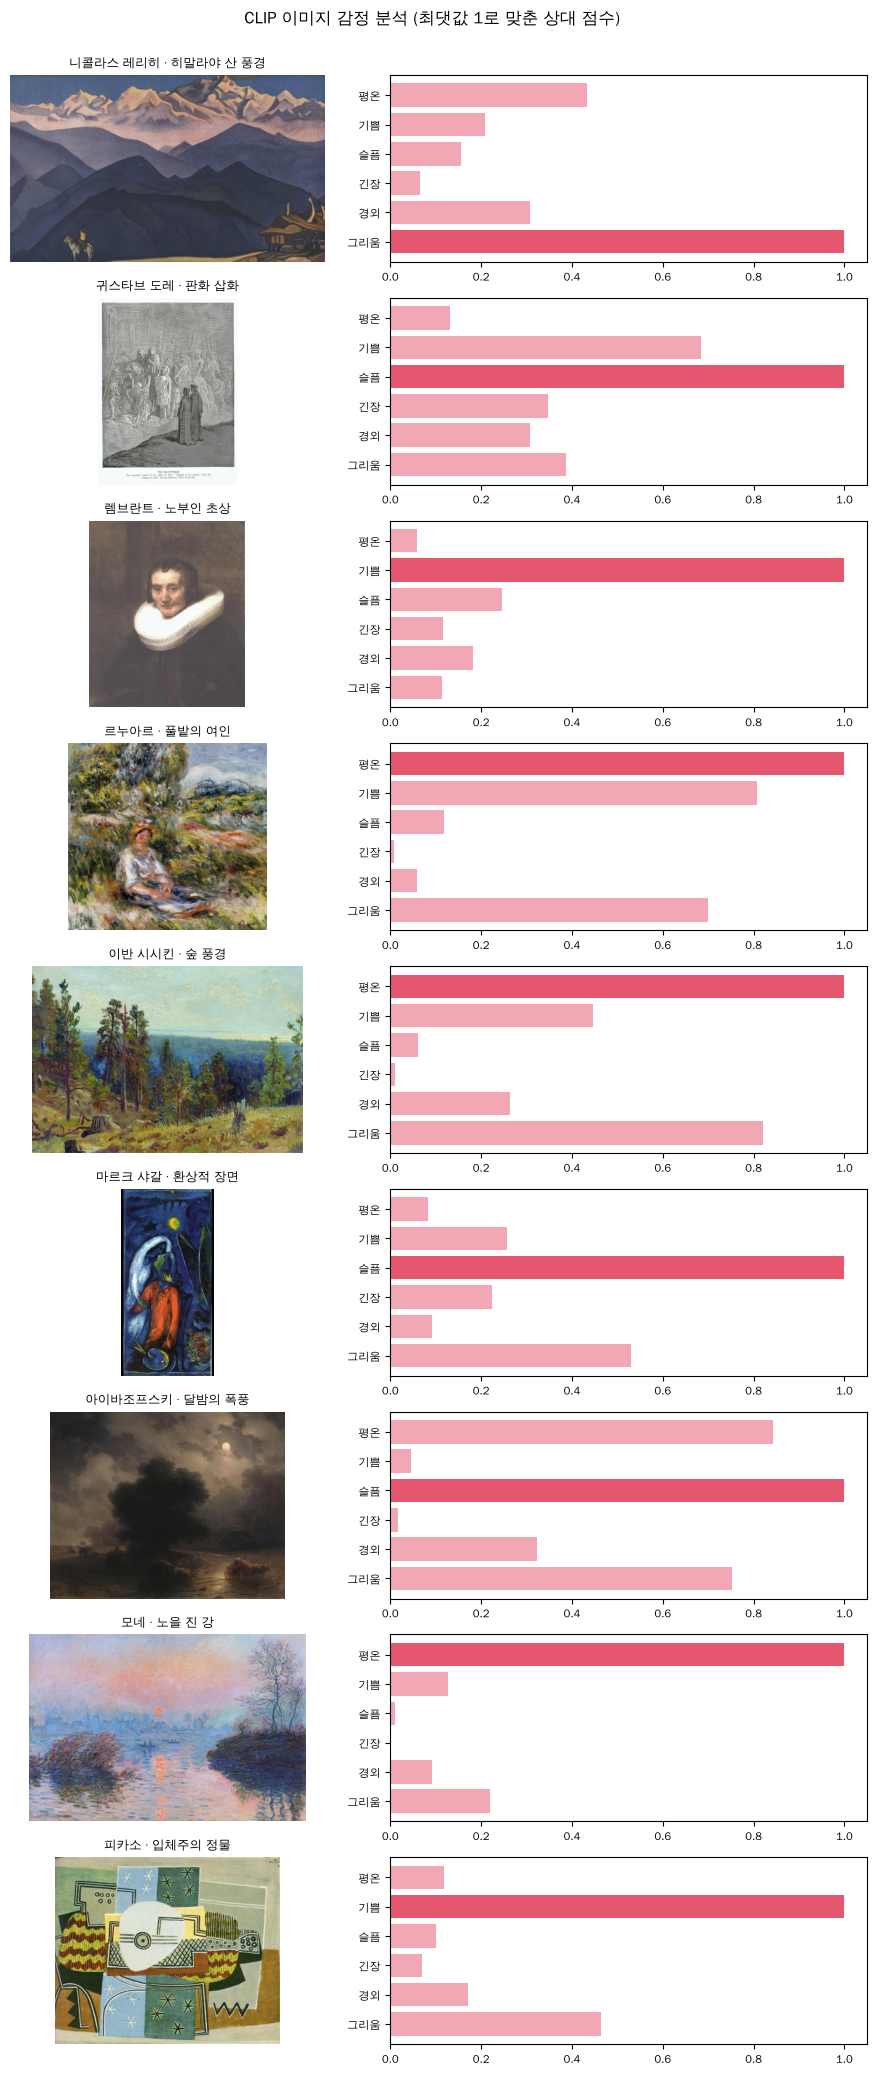

,그림,1위,2위
0,니콜라스 레리히 · 히말라야 산 풍경,그리움,평온
1,귀스타브 도레 · 판화 삽화,슬픔,기쁨
2,렘브란트 · 노부인 초상,기쁨,슬픔
3,르누아르 · 풀밭의 여인,평온,기쁨
4,이반 시시킨 · 숲 풍경,평온,그리움
5,마르크 샤갈 · 환상적 장면,슬픔,그리움
6,아이바조프스키 · 달밤의 폭풍,슬픔,평온
7,모네 · 노을 진 강,평온,그리움
8,피카소 · 입체주의 정물,기쁨,그리움


In [20]:
gallery = []
for idx, label in WIKIART:
    img = wikiart_image(idx)
    img.thumbnail((512, 512))  # CLIP은 224×224로 줄여서 보므로 결과는 같고, 그래프 용량만 줄어듦
    scores = scale_to_max(normalize_sum(scorer.image_scores(img)))
    gallery.append((label, img, scores))

fig, axes = plt.subplots(len(gallery), 2, figsize=(9, 2.3 * len(gallery)), gridspec_kw={"width_ratios": [1, 1.4]})
for r, (label, img, scores) in enumerate(gallery):
    axes[r][0].imshow(img); axes[r][0].axis("off"); axes[r][0].set_title(label, fontsize=9)
    vals = [scores[k] for k in EMOTION_KEYS]
    colors = ["#e5576f" if v == max(vals) else "#f2a7b4" for v in vals]
    axes[r][1].barh(KO_LIST[::-1], vals[::-1], color=colors[::-1]); axes[r][1].set_xlim(0, 1.05)
    axes[r][1].tick_params(labelsize=8)
fig.suptitle("CLIP 이미지 감정 분석 (최댓값 1로 맞춘 상대 점수)", y=1.0)
fig.tight_layout(); save(fig, "06_clip_gallery", dpi=80); plt.show()

pd.DataFrame([{"그림": l, "1위": KO[max(s, key=s.get)], "2위": KO[sorted(s, key=s.get)[-2]]} for l, _, s in gallery])

### 2-8. 이미지 + 텍스트를 합치면 — 「인상, 해돋이」 해설 + 모네의 노을 그림

서비스는 이미지 60% + 텍스트 40%로 합칩니다(`config.IMAGE_WEIGHT`).
목업 작품 「인상, 해돋이」(정답: 평온·그리움)의 **해설**과, 2-7의 **모네 노을 그림**(같은 화가·비슷한 주제의 대체 이미지)으로 세 가지를 비교합니다.

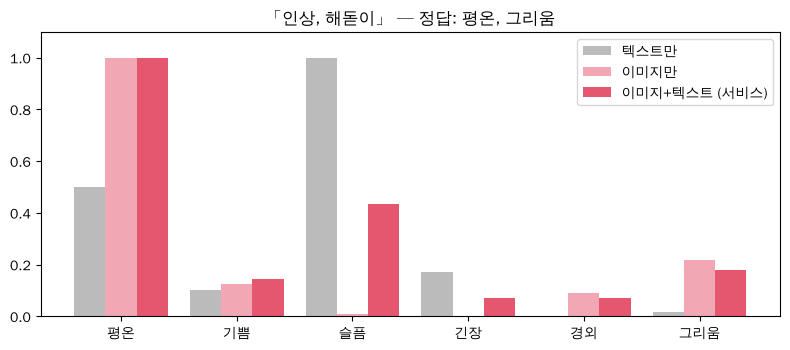

텍스트만       1·2위: 슬픔, 평온
이미지만       1·2위: 평온, 그리움
이미지+텍스트    1·2위: 평온, 슬픔


In [21]:
it5 = next(it for it in items if it["id"] == "aw-05")
txt5 = final_service["aw-05"]
img5 = next(s for l, _, s in gallery if l.startswith("모네"))
both5 = combine(img5, txt5, config.IMAGE_WEIGHT)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(6)
for off, (name, s, c) in zip([-0.27, 0, 0.27], [("텍스트만", txt5, "#bbb"), ("이미지만", img5, "#f2a7b4"), ("이미지+텍스트 (서비스)", both5, "#e5576f")]):
    ax.bar(x + off, [s[k] for k in EMOTION_KEYS], 0.27, label=name, color=c)
ax.set_xticks(x, KO_LIST); ax.set_ylim(0, 1.1)
ax.set_title(f"「{it5['title']}」 — 정답: " + ", ".join(KO[e] for e in it5["expected"]))
ax.legend(); fig.tight_layout(); save(fig, "07_image_text_combined"); plt.show()

for name, s in [("텍스트만", txt5), ("이미지만", img5), ("이미지+텍스트", both5)]:
    top = sorted(EMOTION_KEYS, key=s.get, reverse=True)[:2]
    print(f"{name:10s} 1·2위: {KO[top[0]]}, {KO[top[1]]}")

## 3부. 팀 라벨 일치도 — 감정 정답의 근거 만들기

정답을 1명이 정하면 그 사람의 감각이 기준이 됩니다. 팀원 여러 명이 **각자** 라벨을 달고 비교하면,
① 사람끼리 얼마나 일치하는지(**과제 자체의 난이도**), ② 다수결 정답으로 본 AI 정확도를 함께 얻을 수 있습니다.

**방법:** `evaluation/team_labels.csv`를 만들고 아래 형식으로 채운 뒤 이 셀을 다시 실행하세요.

```csv
id,평가자,감정1,감정2
aw-01,김광권,경외,긴장
aw-01,임준억,긴장,
aw-02,김광권,평온,
...
```

In [22]:
LABEL_FILE = Path("evaluation/team_labels.csv")
KO2KEY = {v: k for k, v in KO.items()}

if not LABEL_FILE.exists():
    print(f"{LABEL_FILE} 이 아직 없습니다. 팀원 2명 이상의 라벨을 모으면 일치도와 다수결 정확도를 계산합니다.")
else:
    lab = pd.read_csv(LABEL_FILE, encoding="utf-8-sig").fillna("")
    raters = sorted(lab["평가자"].unique())
    sets = {(r.id, r.평가자): {KO2KEY[e] for e in (r.감정1, r.감정2) if e} for r in lab.itertuples()}
    ids = [it["id"] for it in items if all((it["id"], p) in sets for p in raters)]
    print(f"평가자 {len(raters)}명 · 공통 작품 {len(ids)}점")

    # (1) 평가자 쌍별 일치도: 대표 감정(감정1) 일치율, 감정 집합이 하나라도 겹치는 비율
    pair_rows = []
    for a, b in combinations(raters, 2):
        first = np.mean([lab[(lab.id == i) & (lab.평가자 == a)].감정1.iat[0] == lab[(lab.id == i) & (lab.평가자 == b)].감정1.iat[0] for i in ids])
        overlap = np.mean([bool(sets[(i, a)] & sets[(i, b)]) for i in ids])
        pair_rows.append({"평가자 쌍": f"{a} – {b}", "대표 감정 일치": first, "하나라도 겹침": overlap})
    display(pd.DataFrame(pair_rows).style.format({"대표 감정 일치": "{:.0%}", "하나라도 겹침": "{:.0%}"}))

    # (2) Fleiss' kappa (대표 감정 기준, 우연히 일치할 확률을 뺀 일치도: 0.2↓ 약함, 0.4~0.6 보통, 0.6↑ 상당)
    n = len(raters)
    counts = np.array([[sum(lab[(lab.id == i) & (lab.평가자 == p)].감정1.iat[0] == KO[k] for p in raters) for k in EMOTION_KEYS] for i in ids])
    p_i = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    p_j = counts.sum(axis=0) / counts.sum()
    kappa = (p_i.mean() - (p_j ** 2).sum()) / (1 - (p_j ** 2).sum())
    print(f"Fleiss' kappa = {kappa:.2f}")

    # (3) 다수결 정답(2명 이상이 고른 감정, 없으면 최다 득표)으로 AI 정확도 다시 계산
    majority = {}
    for i in ids:
        votes = pd.Series([e for p in raters for e in sets[(i, p)]]).value_counts()
        majority[i] = set(votes[votes >= 2].index) or {votes.index[0]}
    t1 = np.mean([rank_loo[i][0] in majority[i] for i in ids])
    t2 = np.mean([bool(set(rank_loo[i][:2]) & majority[i]) for i in ids])
    print(f"다수결 정답 기준 AI 정확도 (교차검증 보정): Top-1 {t1:.0%}, Top-2 {t2:.0%}")

evaluation/team_labels.csv 이 아직 없습니다. 팀원 2명 이상의 라벨을 모으면 일치도와 다수결 정확도를 계산합니다.


## 결론

### 숫자 요약 (이번 실행)

In [23]:
summary = {
    "태그 검증 그림 수 (WikiArt)": len(tag_df),
    **{f"태그 「{t}」 정확도 · AUC": f"{m['정확도']:.0%} · {m['AUC']:.2f}" for t, m in subject_metrics.iterrows()},
    "「추상」 평균 (입체주의 / 그 외)": f"{tag_df[tag_df.group == 'cubism'].abstract.mean():.2f} / {tag_df[tag_df.group != 'cubism'].abstract.mean():.2f}",
    **{f"「{t}」 ↔ 픽셀 상관": f"{r:.2f}" for t, r in color_corr.items()},
    **({f"캡처 {capture_metrics['작품 수']}점 대표 태그 적중률 (0.5 → 태그별 기준값 → 교차검증)":
        " → ".join(f"{v:.0%}" for k, v in capture_metrics.items() if k.endswith("적중률"))} if capture_metrics else {}),
    "감정(텍스트) 보정 후 Top-1 · Top-2": f"{acc.iloc[2]['Top-1']:.0%} · {acc.iloc[2]['Top-2']:.0%} (무작위 {rand_top1:.0%} · {rand_top2:.0%})",
}
pd.Series(summary, name="값").to_frame()

,값
태그 검증 그림 수 (WikiArt),70
태그 「풍경」 정확도 · AUC,96% · 1.00
태그 「인물」 정확도 · AUC,91% · 0.98
「추상」 평균 (입체주의 / 그 외),0.44 / 0.19
「강렬한 색감」 ↔ 픽셀 상관,0.46
「빛」 ↔ 픽셀 상관,-0.19
「따뜻한 색감」 ↔ 픽셀 상관,0.56
「차가운 색감」 ↔ 픽셀 상관,0.47
「부드러운 색감」 ↔ 픽셀 상관,0.30
캡처 40점 대표 태그 적중률 (0.5 → 태그별 기준값 → 교차검증),90% → 90% → 88%


### 해석

(2026-10-29 실행 결과를 보고 작성 — 캡처 40점 정답을 팀원 6명 다수결로 바꾼 뒤. 데이터를 바꿔 다시 실행했다면 함께 고쳐 주세요)

**1. 소재 태그(풍경·인물)는 정확하다 — 데이터셋의 공식 장르 정답 기준**
- 풍경 **96% (AUC 1.00)**, 인물 **91% (AUC 0.98)** (기준값 0.5 — 예전 인물 기준값 0.55에서는 93%). 개발자가 정한 정답이 아니라 WikiArt 장르 라벨로 검증해 근거가 강하다.
- 인물 오답은 사람이 작게 들어간 풍경화·정물화를 "인물"로 본 경우(정밀도 80%, 재현율 100%).
- 감정 분석(텍스트 Top-1 45%)보다 훨씬 정확 → **추천 기준을 감정에서 태그로 바꾼 근거**가 된다.

**캡처 40점 — 팀원 6명 다수결 정답 (2026-10-29)**
- 정답: 팀원 6명이 각자 라벨(구글 폼 4명 · 라벨링 페이지 2명) → 다수결. 김동섭은 그림마다 태그를 1개만 골라 대표 태그에만 반영(1-8-2).
- **사람끼리 일치도(kappa)**: 인물 0.88 · 추상 0.62 · 풍경 0.59 · 차가운 0.51 · 따뜻한 0.47 · 빛 0.42 · 강렬한 0.38 · 부드러운 0.26 · 대표 태그 0.40. **색감·빛은 사람끼리도 많이 갈린다.**
- **AI AUC (다수결 정답)**: 0.84~0.98 — 8개 태그 모두 0.8 이상. 개발자 1인 정답일 때(0.84~0.98)와 비슷해, 정답을 바꿔도 AI의 순서 매기기는 그대로 유효하다.
- **AI vs 사람 1명** (나머지 평가자 다수결과 같은 비율): 추상 95% vs 93%, 부드러운 93% vs 84%, 빛 89% vs 90%, 인물 89% vs 96%, 따뜻한 82% vs 86%, 풍경 81% vs 88%, 강렬한 79% vs 88%, 차가운 79% vs 88%. **추상·부드러운·빛은 사람 수준 이상**, 강렬한·차가운·풍경은 사람보다 7~9%p 낮다.
- **「빛」 문장 개선** (10/27): 어둠 속 광원·햇빛·명암 대비 문장으로 바꿔 「빛」 AUC 0.59 → 0.84 (1인 정답 기준), 팀 정답 기준 0.95.
- **태그별 기준값** (`app/tag_calibration.json`): 팀 정답으로 다시 정함. F1이 가장 높은 기준값을 구하고 **교차검증에서 0.5보다 F1이 나아진 태그에만** 적용 — 빛 0.95 · 강렬한 0.90 · 따뜻한 0.90, 나머지 0.5. (예전 1인 정답 값: 풍경 0.60 · 인물 0.55 · 빛 0.90 · 따뜻한 0.95 · 부드러운 0.20)
- 대표 태그 적중률: 0.5 기준 90% · 서비스 기준값 90% · **교차검증 88%**. 놓친 4점은 폴록 「가을의 리듬」(추상), 모네 「루앙 대성당」·드랭 「채링 크로스 다리」·이중섭 「황소」(팀 다수결 대표가 풍경). 뒤의 셋은 건물·도시·동물을 「풍경」으로 볼지의 **정의 문제**라, 태그 기준표에 정하면 좋다.

**2. 추상은 경향만 확인**
- 입체주의 평균 0.44 vs 그 외 0.19 (0.5 이상 40% vs 10~20%). 방향은 맞지만 이 데이터에는 진짜 추상화가 거의 없다. 캡처 40점에서는 팀 정답 기준 AUC 0.98, 폴록만 놓쳤다.

**3. 색 태그는 실제 픽셀 색과 중간 정도로 일치**
- 픽셀 측정값과 순위 상관: 따뜻한 0.56 · 차가운 0.47 · 강렬한 0.46 · 부드러운 0.30.
- 채도만 바꾼 실험에서 「강렬한 색감」이 채도를 따라 꾸준히 올라가고, 어두운 렘브란트 초상은 낮게 유지 → **소재가 아니라 색을 보고 판단**한다.
- 따뜻한/차가운 색감은 같은 문장 쌍을 반대로 쓰는 구조라 **모든 그림이 둘 중 한쪽으로 기운다**. 이 샘플은 픽셀로 재도 74%가 따뜻한 색 우세(옛 유화의 갈색·황금색)라 AI도 86%를 따뜻한 색감으로 봤다. "중립 색" 문장을 더한 대안은 픽셀과의 일치가 더 낮아(67~74%) 현행을 유지했다.

**4. 「빛」은 문장을 바꿔 크게 나아졌지만 여전히 가장 약하다**
- 사람끼리도 갈리는 태그(kappa 0.42)지만, 팀 정답 기준 AUC 0.95, 기준값 0.95를 적용하면 사람 1명과 비슷하게 맞힌다(89% vs 90%). 새 문장은 어둠 속 광원을 '빛'으로 보므로 평균 밝기와는 오히려 음의 상관(WikiArt -0.19) — '빛'은 밝기가 아니라 광원·광채라 픽셀로 검증하기 어렵다. 관리자 확인이 특히 필요한 태그.

**5. 감정 분석은 설명용으로만**
- 텍스트 Top-1 45% · Top-2 73%(무작위 27% · 50%), '경외' 쏠림. 추천에는 쓰지 않고 작품 분위기 설명·아트 영수증에만 쓴다.

### 한계와 다음 단계
| 한계 | 다음 단계 |
|---|---|
| 캡처 40점(태그마다 5점)·작품을 개발자가 고름 | 실제 전시(유영국) 작품 약 20점으로 같은 측정 |
| 색감·빛은 사람끼리도 갈림 (kappa 0.26~0.51) | 태그 기준표를 더 구체적으로(예: 건물·동물도 풍경인가) → 다시 라벨하면 일치도가 오르는지 확인 |
| 강렬한·차가운 색감은 사람보다 7~9%p 낮음 | 문장 후보 비교(「빛」처럼), 픽셀 측정값과 섞기(차가운 색감은 픽셀 AUC가 더 높았음) |
| 파인튜닝 없음(제로샷) | 라벨이 200~400점 모이면 CLIP 리니어 프로브(CPU 가능)로 태그별 분류기 학습 |
